# UK fuel prices 2018–2026: a data detective project

**Data:** Weekly average UK pump prices for unleaded petrol (ULSP) and diesel (ULSD), published by the
Department for Energy Security and Net Zero (DESNZ). There are 464 weeks of data, from 1 January 2018 to 16 November 2026.

**Three questions:**
1. When were prices highest, and when were they lowest?
2. How fast can prices rise?
3. Why does diesel now cost so much more than petrol?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Colours: one fixed colour per fuel, used the same way in every chart
PETROL, DIESEL = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (11, 5.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Load the data

In [2]:
raw = pd.read_csv("data/weekly_road_fuel_prices_2018_2026.csv")
print(raw.shape)
raw.head()

(464, 7)


,Date,ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre,ULSD (Ultra low sulphur diesel) Pump price in pence/litre,ULSP (Ultra low sulphur unleaded petrol) Duty rate in pence/litre,ULSD (Ultra low sulphur diesel) Duty rate in pence/litre,ULSP (Ultra low sulphur unleaded petrol) VAT percentage rate,ULSD (Ultra low sulphur diesel) VAT percentage rate
0,01/01/2018,120.19,123.51,57.95,57.95,20,20
1,08/01/2018,120.52,123.97,57.95,57.95,20,20
2,15/01/2018,120.96,124.58,57.95,57.95,20,20
3,22/01/2018,121.50,125.07,57.95,57.95,20,20
4,29/01/2018,121.69,125.32,57.95,57.95,20,20


## 2. Clean it

The file is official, so it's fairly tidy. It still has three traps that would quietly produce wrong answers:

* **Column names** are 80+ characters long. I rename them to something you can actually type.
* **Dates are in UK format (dd/mm/yyyy).** Left alone, pandas can read `03/02/2020` as **2 March** instead of **3 February**, and the chart would be scrambled without any error. So I give it the exact format.
* **Blank rows, duplicate weeks and missing weeks.** I check for all three rather than assuming there are none.

In [3]:
df = raw.copy()
df.columns = ["date", "petrol", "diesel", "petrol_duty", "diesel_duty", "petrol_vat", "diesel_vat"]

# Fix the dates: tell pandas the exact UK format so nothing gets misread
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")

# Remove blank rows (a row with no price is useless)
before = len(df)
df = df.dropna(subset=["petrol", "diesel"])
print(f"Blank rows removed: {before - len(df)}")

# Remove duplicate weeks, keep the data in date order
df = df.drop_duplicates(subset="date").sort_values("date").set_index("date")

# Check every row is exactly 7 days after the one before (no missing weeks)
gaps = df.index.to_series().diff().dt.days.dropna()
print(f"Weeks: {len(df)} | from {df.index.min():%d %b %Y} to {df.index.max():%d %b %Y}")
print(f"Missing weeks: {(gaps != 7).sum()}")

# Sanity check: prices should be in a believable range (pence per litre)
assert df["petrol"].between(80, 250).all() and df["diesel"].between(80, 250).all(), "Price outside believable range"
df[["petrol", "diesel"]].describe().round(1)

Blank rows removed: 0
Weeks: 464 | from 01 Jan 2018 to 16 Nov 2026
Missing weeks: 0


,petrol,diesel
count,464.0,464.0
mean,137.4,146.1
std,16.9,21.3
min,104.9,111.7
25%,125.8,131.3
50%,134.7,141.9
75%,146.9,156.2
max,191.6,200.0


## Question 1: When were prices highest, and when were they lowest?

Lowest:  petrol 104.87p (25 May 2020), diesel 111.70p (25 May 2020)
Highest: petrol 191.55p (04 Jul 2022), diesel 200.04p (12 Oct 2026)


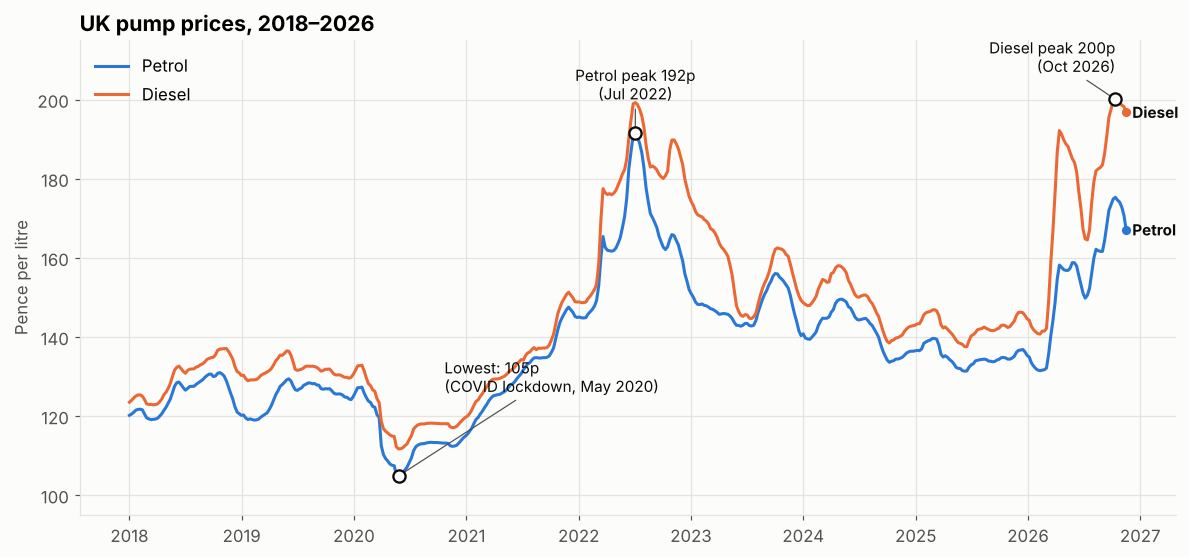

In [4]:
low_p, low_d = df["petrol"].idxmin(), df["diesel"].idxmin()
high_p, high_d = df["petrol"].idxmax(), df["diesel"].idxmax()
print(f"Lowest:  petrol {df.petrol.min():.2f}p ({low_p:%d %b %Y}), diesel {df.diesel.min():.2f}p ({low_d:%d %b %Y})")
print(f"Highest: petrol {df.petrol.max():.2f}p ({high_p:%d %b %Y}), diesel {df.diesel.max():.2f}p ({high_d:%d %b %Y})")

fig, ax = plt.subplots()
ax.plot(df.index, df["petrol"], color=PETROL, label="Petrol")
ax.plot(df.index, df["diesel"], color=DIESEL, label="Diesel")

def note(x, y, text, dy, ha="center", dx=0):
    ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha,
                fontsize=10, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    ax.plot(x, y, "o", ms=8, color="#fcfcfb", mec=INK, mew=1.5, zorder=5)

note(low_p, df.petrol.min(), f"Lowest: {df.petrol.min():.0f}p\n(COVID lockdown, May 2020)", 55, ha="left", dx=30)
note(high_p, df.petrol.max(), f"Petrol peak {df.petrol.max():.0f}p\n(Jul 2022)", 22)
note(high_d, df.diesel.max(), f"Diesel peak {df.diesel.max():.0f}p\n(Oct 2026)", 18, ha="right")

# Direct labels at the end of each line
for col, colour in [("petrol", PETROL), ("diesel", DIESEL)]:
    ax.text(df.index[-1] + pd.Timedelta(days=20), df[col].iloc[-1], col.title(),
            color=INK, va="center", fontsize=10, fontweight="bold")
    ax.plot(df.index[-1], df[col].iloc[-1], "o", ms=5, color=colour)

ax.set_title("UK pump prices, 2018–2026")
ax.set_ylabel("Pence per litre")
ax.set_ylim(95, 215)
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig("charts/1_prices_over_time.png", bbox_inches="tight")
plt.show()

**What it means:** Fuel was cheapest in May 2020, when lockdown emptied the roads (petrol 104.87p). It was most expensive in two separate crises: petrol peaked at 191.55p in July 2022, and diesel went above **£2 a litre (200.04p) for the first time in this data in October 2026**.

Prices don't drift up gently. They sit flat for long stretches, then jump in response to world events, and they fall back much more slowly than they rose.

## Question 2: How fast can prices rise?

The weekly change is noisy, so I use the change over **4 weeks** (roughly one month). It's a fairer way to compare price shocks.

Biggest 4-week rise in petrol: +20.6p (4 weeks to 27 Jun 2022)
Biggest 4-week rise in diesel: +37.7p (4 weeks to 06 Apr 2026)
2022: fastest diesel rise +25.5p in 4 weeks (to 21 Mar)
2026: fastest diesel rise +37.7p in 4 weeks (to 06 Apr)


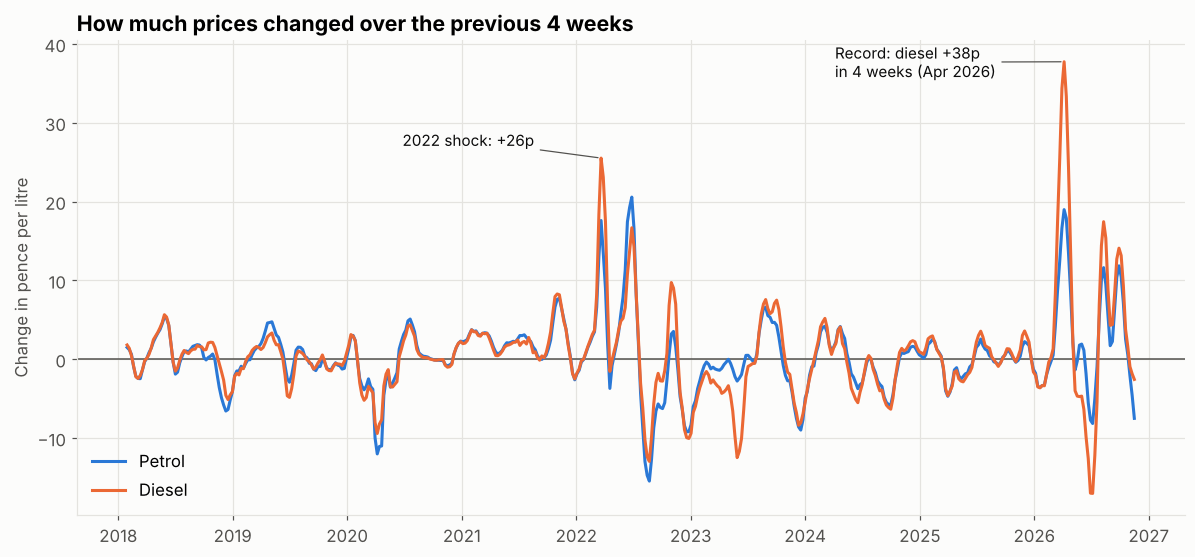

In [5]:
change_4w = df[["petrol", "diesel"]].diff(4)

for col in ["petrol", "diesel"]:
    when = change_4w[col].idxmax()
    print(f"Biggest 4-week rise in {col}: +{change_4w[col].max():.1f}p (4 weeks to {when:%d %b %Y})")

# Compare the two big shocks: 2022 vs 2026
for year in ["2022", "2026"]:
    peak = change_4w.loc[year, "diesel"]
    print(f"{year}: fastest diesel rise +{peak.max():.1f}p in 4 weeks (to {peak.idxmax():%d %b})")

fig, ax = plt.subplots()
ax.axhline(0, color=MUTED, lw=1)
ax.plot(change_4w.index, change_4w["petrol"], color=PETROL, label="Petrol")
ax.plot(change_4w.index, change_4w["diesel"], color=DIESEL, label="Diesel")

rec = change_4w["diesel"].idxmax()
ax.annotate(f"Record: diesel +{change_4w.diesel.max():.0f}p\nin 4 weeks (Apr 2026)", (rec, change_4w.diesel.max()),
            xytext=(-150, -10), textcoords="offset points", fontsize=10, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
r22 = change_4w.loc["2022", "diesel"].idxmax()
ax.annotate(f"2022 shock: +{change_4w.loc['2022','diesel'].max():.0f}p", (r22, change_4w.loc[r22, "diesel"]),
            xytext=(-130, 8), textcoords="offset points", fontsize=10, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

ax.set_title("How much prices changed over the previous 4 weeks")
ax.set_ylabel("Change in pence per litre")
ax.legend(loc="lower left")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig("charts/2_speed_of_change.png", bbox_inches="tight")
plt.show()

**What it means:** In the four weeks to 6 April 2026, diesel rose **37.7p a litre**. That's the fastest rise in this dataset, about half as fast again as the worst month of the 2022 energy crisis (+25.5p). Over the same period petrol rose 19.0p, so this shock hit diesel twice as hard.

The timing matches news reports of conflict involving Iran disrupting oil shipping through the Strait of Hormuz in March 2026. A price shock can now add around £20 to the cost of filling a 55-litre diesel tank in just one month.

## Question 3: Why does diesel now cost so much more than petrol?

Diesel and petrol pay the same fuel duty (52.95p a litre since March 2022) and the same 20% VAT, so tax can't explain a gap between them. Any difference has to come from the cost of the fuel itself.

Same duty and VAT for both fuels every week: True
date
2018     5.0
2019     6.7
2020     5.4
2021     3.6
2022    13.1
2023    10.5
2024     6.9
2025     7.6
2026    20.9
Biggest gap: 34.0p (13 Apr 2026) | latest: 29.7p


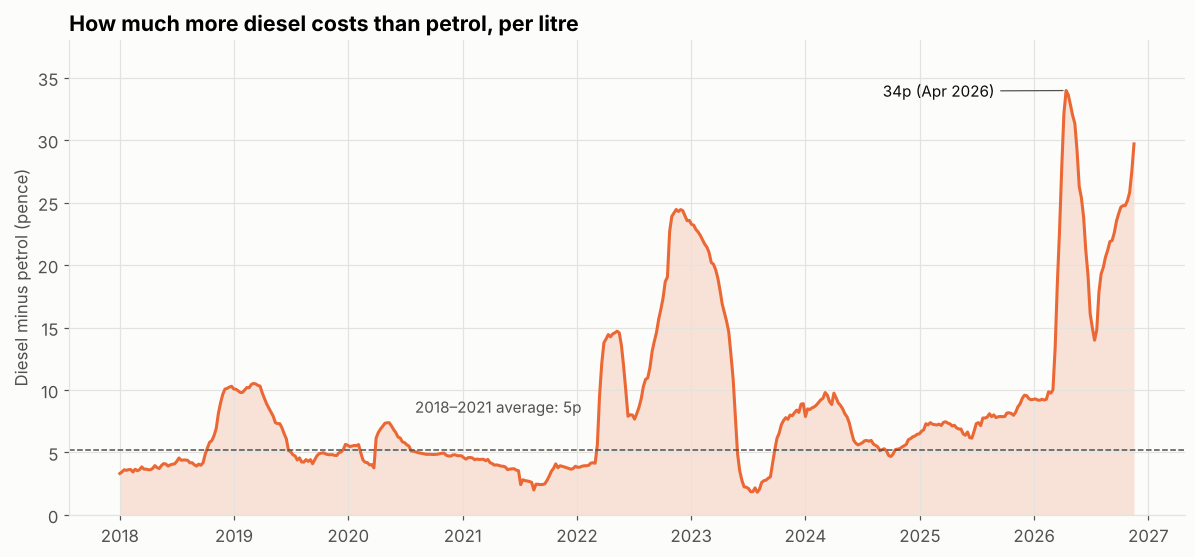

In [6]:
# Confirm the tax really is the same for both fuels in every week
same_tax = (df.petrol_duty == df.diesel_duty).all() and (df.petrol_vat == df.diesel_vat).all()
print("Same duty and VAT for both fuels every week:", same_tax)

gap = df["diesel"] - df["petrol"]
yearly = gap.resample("YE").mean()
yearly.index = yearly.index.year
print(yearly.round(1).to_string())
print(f"Biggest gap: {gap.max():.1f}p ({gap.idxmax():%d %b %Y}) | latest: {gap.iloc[-1]:.1f}p")

fig, ax = plt.subplots()
ax.fill_between(gap.index, 0, gap, color=DIESEL, alpha=0.18, lw=0)
ax.plot(gap.index, gap, color=DIESEL)
pre = gap.loc[:"2021"].mean()
ax.axhline(pre, color=MUTED, lw=1, ls="--")
ax.text(pd.Timestamp("2020-08-01"), pre + 3.0, f"2018–2021 average: {pre:.0f}p", color=MUTED, fontsize=10)
ax.annotate(f"{gap.max():.0f}p (Apr 2026)", (gap.idxmax(), gap.max()), xytext=(-120, -4),
            textcoords="offset points", fontsize=10, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_title("How much more diesel costs than petrol, per litre")
ax.set_ylabel("Diesel minus petrol (pence)")
ax.set_ylim(0, 38)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig("charts/3_diesel_premium.png", bbox_inches="tight")
plt.show()

**What it means:** From 2018 to 2021 diesel cost about 5p a litre more than petrol. Since April 2026 the gap has averaged around 24p, reaching a record 34p on 13 April 2026 (and it's widening again: 29.7p in the latest week). The tax is identical for both. So the extra cost comes from the fuel itself: the UK imports much of its diesel, and supply shocks hit diesel harder than petrol.

That matters beyond drivers. Lorries, vans and buses run on diesel, so a lasting diesel premium raises the cost of moving goods and feeds into the price of nearly everything in the shops.

## Summary

| Question | Finding |
|---|---|
| When were prices highest? | Petrol peaked at 191.55p (Jul 2022). Diesel peaked at 200.04p (Oct 2026), the first time above £2. The low point was May 2020 (lockdown). |
| How fast can they rise? | Diesel +37.7p in 4 weeks to 6 Apr 2026, the fastest in the data and about 1.5 times the 2022 record. |
| Why is diesel dearer? | Not tax, which is identical. The premium went from ~5p (2018–21) to ~24p since April 2026, driven by the cost of the fuel itself. |

**Limitations:** These are national weekly averages, so prices at individual stations and in different regions vary. The figures aren't adjusted for inflation either, so 2018 pence and 2026 pence aren't directly comparable.